# 05 封顶AQHI：两个基准预测

主实验：17个非塔门站点，过去72小时预测未来24小时，每小时滚动预测。
**目标为封顶AQHI**：1–10保留原值，10+编码为10，原始10+标记另存。这无法区分10和10+，不是对原始指数的精确预测。
带星号的有效观测保留。无插值；输入72小时或目标24小时内任一站点缺测，则整个联合窗口排除。

训练：源日期2020-06至2023-12；验证：2024年；最终测试：2025-01至2026-06，本Notebook不计算其成绩。
延续源小时24转次日00:00规则。按目标区间分组，验证可使用预测时点之前已观测到的历史。
来源：[香港环保署历史AQHI](https://data.gov.hk/sc-data/dataset/hk-epd-airteam-past-record-of-air-quality-health-index-sc)。


In [1]:
from pathlib import Path
from datetime import datetime
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
ROOT=Path.cwd()
if not (ROOT/'src/aqhi_data.py').exists(): ROOT=ROOT.parent
design_files=sorted((ROOT/'data/processed/design').glob('*/design.json'))
assert design_files, '请先运行04'
design=json.loads(design_files[-1].read_text(encoding='utf-8'))
SOURCE=Path(design['source'])
STATIONS=design['comparison_targets']
assert len(STATIONS)==17 and 'Tap Mun' not in STATIONS
L,H=design['lookback'],design['horizon']
assert (L,H)==(72,24)
train_end=pd.Timestamp(design['train_end_inclusive']).tz_convert('Asia/Hong_Kong')
val_end=pd.Timestamp(design['validation_end_inclusive']).tz_convert('Asia/Hong_Kong')
h=pd.read_csv(SOURCE/'history_all_audited.csv.gz',keep_default_na=False,dtype={'source_date':str})
h=h.loc[h.source_date.ge('2020-06-01') & h.station_id.isin(STATIONS)].copy()
h['timestamp']=pd.to_datetime(h.timestamp,utc=True).dt.tz_convert('Asia/Hong_Kong')
# 在计算特征、窗口及指标之前，排除最终测试期。
h=h.loc[h.timestamp.le(val_end)].copy()
for col in ['is_10_plus','is_substituted']:
    if h[col].dtype!=bool:
        assert h[col].astype(str).isin(['True','False']).all()
        h[col]=h[col].astype(str).eq('True')
h['capped_aqhi']=pd.to_numeric(h.aqhi_value,errors='coerce')
h.loc[h.is_10_plus,'capped_aqhi']=10.0
assert h.loc[h.is_10_plus,'capped_aqhi'].eq(10).all()
assert not h.duplicated(['timestamp','station_id']).any()
index=pd.date_range(h.timestamp.min(),val_end,freq='h')
panel=h.pivot(index='timestamp',columns='station_id',values='capped_aqhi').reindex(index=index,columns=STATIONS)
cap=h.pivot(index='timestamp',columns='station_id',values='is_10_plus').reindex(index=index,columns=STATIONS).fillna(False).astype(bool)
star=h.pivot(index='timestamp',columns='station_id',values='is_substituted').reindex(index=index,columns=STATIONS).fillna(False).astype(bool)
OUT=ROOT/'data/processed/baselines'/datetime.now().strftime('%Y%m%d_%H%M%S_%f')
OUT.mkdir(parents=True,exist_ok=False)
print('输出目录：',OUT)
print('目标：封顶AQHI；测试集未参与指标计算。')

输出目录： C:\Users\hxq08259\Desktop\sem1\Math7005\data\processed\baselines\20261110_181540_048535
目标：封顶AQHI；测试集未参与指标计算。


## 1. 固定共同预测窗口

预测起点表示第一个待预测小时。两个基准与后续TSMixer使用同样的72+24小时完整窗口标准。
每天有24个重叠起点，因此指标中的观测重复参与不同预测时长，不是独立样本。


In [2]:
arr=panel.to_numpy(dtype=float)
all_present=pd.Series(np.isfinite(arr).all(axis=1),index=index)
input_ok=all_present.astype(int).rolling(L).sum().shift(1).eq(L)
target_ok=all_present.astype(int).rolling(H).sum().shift(-(H-1)).eq(H)
end=index+pd.Timedelta(hours=H-1)
train_mask=(index<=train_end)&(end<=train_end)&input_ok.to_numpy()&target_ok.to_numpy()
val_mask=(index>train_end)&(end<=val_end)&input_ok.to_numpy()&target_ok.to_numpy()
origins=np.flatnonzero(val_mask)
assert len(origins)>0
gap_start=pd.Timestamp('2023-08-25 01:00',tz='Asia/Hong_Kong')
gap_end=pd.Timestamp('2023-09-01 00:00',tz='Asia/Hong_Kong')
for selected in [np.flatnonzero(train_mask),origins]:
    assert not (((index[selected]-pd.Timedelta(hours=L))<=gap_end)&(end[selected]>=gap_start)).any()
assert index[origins].min()>train_end and end[origins].max()<=val_end
target_indices=origins[:,None]+np.arange(H)[None,:]
y=arr[target_indices]
y_cap=cap.to_numpy()[target_indices]
y_star=star.to_numpy()[target_indices]
assert y.shape==(len(origins),H,len(STATIONS)) and np.isfinite(y).all()
print('训练期可用联合窗口：',int(train_mask.sum()))
print('验证期可用联合窗口：',len(origins))
print('验证目标形状（起点、未来小时、站点）：',y.shape)
pd.DataFrame({'forecast_start':index[np.flatnonzero(train_mask)]}).to_csv(OUT/'train_origins.csv',index=False)
pd.DataFrame({'forecast_start':index[origins]}).to_csv(OUT/'validation_origins.csv',index=False)

训练期可用联合窗口： 28957
验证期可用联合窗口： 8760
验证目标形状（起点、未来小时、站点）： (8760, 24, 17)


## 2. 两个无训练参数基准

- Persistence：未来24小时均等于最后已观测小时。
- Previous day：每个待预测小时取其前24小时的观测。

预测未来第24小时使用的是起点前1小时，仍属于已观测数据。所有索引均先检查，避免偷看目标。


In [3]:
lag_indices=target_indices-24
assert (lag_indices<origins[:,None]).all()
assert (lag_indices>=origins[:,None]-L).all()
predictions={
    'Persistence':np.repeat(arr[origins-1,None,:],H,axis=1),
    'Previous day':arr[lag_indices]
}
# 合成序列边界测试：起点72的24小时目标为72..95，前一天值为48..71。
assert np.array_equal(np.arange(72,96)-24,np.arange(48,72))
for p in predictions.values():
    assert p.shape==y.shape and np.isfinite(p).all()
def metric(truth,pred):
    err=pred-truth
    return {'n_forecasts':int(err.size),'MAE':float(np.abs(err).mean()) if err.size else None,
            'RMSE':float(np.sqrt(np.square(err).mean())) if err.size else None,
            'bias':float(err.mean()) if err.size else None}
overall=[]; horizon=[]; station=[]; subsets=[]
subset_masks={'all':np.ones(y.shape,dtype=bool),'target_at_least_7':y>=7,
              'original_10_plus':y_cap,'target_substituted':y_star,'target_non_substituted':~y_star}
for name,pred in predictions.items():
    overall.append({'model':name,**metric(y,pred)})
    for j in range(H): horizon.append({'model':name,'horizon':j+1,**metric(y[:,j,:],pred[:,j,:])})
    for j,s in enumerate(STATIONS): station.append({'model':name,'station_id':s,**metric(y[:,:,j],pred[:,:,j])})
    for label,mask in subset_masks.items():
        unique_indices=np.unique(target_indices)
        unique_y=arr[unique_indices]
        unique_cap=cap.to_numpy()[unique_indices]
        unique_star=star.to_numpy()[unique_indices]
        unique_mask={'all':np.ones(unique_y.shape,dtype=bool),'target_at_least_7':unique_y>=7,
          'original_10_plus':unique_cap,'target_substituted':unique_star,'target_non_substituted':~unique_star}[label]
        subsets.append({'model':name,'subset':label,'unique_station_hours':int(unique_mask.sum()),**metric(y[mask],pred[mask])})
overall=pd.DataFrame(overall); horizon=pd.DataFrame(horizon)
station=pd.DataFrame(station); subsets=pd.DataFrame(subsets)
display(overall.round(4))
display(subsets.round(4))

,model,n_forecasts,MAE,RMSE,bias
0,Persistence,3574080,0.6630,1.0501,0.0002
1,Previous day,3574080,0.6163,0.9638,-0.0013


,model,subset,unique_station_hours,n_forecasts,MAE,RMSE,bias
0,Persistence,all,149311,3574080,0.6630,1.0501,0.0002
1,Persistence,target_at_least_7,1860,43682,2.7508,3.2048,-2.6531
2,Persistence,original_10_plus,14,336,5.4048,5.7972,-5.4048
3,Persistence,target_substituted,3440,82496,0.6551,1.0224,-0.1368
4,Persistence,target_non_substituted,145871,3491584,0.6632,1.0508,0.0035
5,Previous day,all,149311,3574080,0.6163,0.9638,-0.0013
6,Previous day,target_at_least_7,1860,43682,2.2932,2.6283,-2.1812
7,Previous day,original_10_plus,14,336,4.5714,4.6445,-4.5714
8,Previous day,target_substituted,3440,82496,0.6013,0.9373,-0.0311
9,Previous day,target_non_substituted,145871,3491584,0.6167,0.9644,-0.0006


## 3. 误差随预测时长的变化

MAE、RMSE越低越好；bias为预测减观测的均值。整体指标不能替代高值时段的单独表现。
原始10+子集的误差针对封顶值10，不衡量超过10的实际程度。
以下只报告验证集，不把表现最好的基准自动视作最终模型。


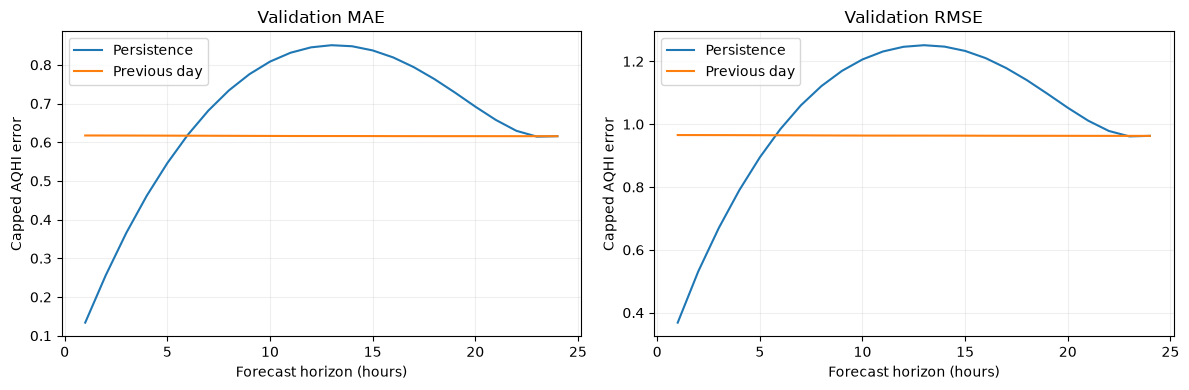

model,Persistence,Previous day
station_id,,
Causeway Bay,0.6719,0.5691
Central,0.6152,0.5868
Central/Western,0.6002,0.6267
Eastern,0.5871,0.5892
Kwai Chung,0.6476,0.5956
Kwun Tong,0.6135,0.6004
Mong Kok,0.6576,0.5900
North,0.7133,0.6446
Sha Tin,0.6719,0.6315


In [4]:
fig,axes=plt.subplots(1,2,figsize=(12,4))
for model,g in horizon.groupby('model'):
    axes[0].plot(g.horizon,g.MAE,label=model)
    axes[1].plot(g.horizon,g.RMSE,label=model)
for ax,title in zip(axes,['Validation MAE','Validation RMSE']):
    ax.set(title=title,xlabel='Forecast horizon (hours)',ylabel='Capped AQHI error')
    ax.legend(); ax.grid(alpha=.2)
fig.tight_layout(); fig.savefig(OUT/'validation_errors_by_horizon.png',dpi=150)
plt.show()
display(station.pivot(index='station_id',columns='model',values='MAE').round(4))

## 4. 保存与下一步

仅保存窗口索引、指标和配置，不保存庞大的重叠预测数组。运行结果可由本Notebook复现。
下一步TSMixer沿用相同站点、目标转换、时间划分和共同验证起点；标准化只在训练期拟合。
最终测试集在模型与参数锁定后统一评估。封顶处理的风险信息损失必须在报告与网站说明。


In [5]:
for name,t in {'overall_validation':overall,'horizon_validation':horizon,
               'station_validation':station,'subset_validation':subsets}.items():
    t.to_csv(OUT/f'{name}.csv',index=False,encoding='utf-8-sig')
config={'source':str(SOURCE),'design_file':str(design_files[-1]),'stations':STATIONS,
 'lookback':L,'horizon':H,'target':'capped AQHI: original 10+ mapped to 10, original flag retained',
 'substituted_records':'retained','missing':'no imputation; require complete 96-hour joint windows',
 'train_end_inclusive':str(train_end),'validation_end_inclusive':str(val_end),
 'train_windows':int(train_mask.sum()),'validation_windows':len(origins),
 'test_evaluated':False,'metrics':'overlapping forecast-origin/horizon/station instances; not independent observations'}
(OUT/'baseline_config.json').write_text(json.dumps(config,ensure_ascii=False,indent=2),encoding='utf-8')
print('基准预测完成；验证指标已保存：',OUT)
print('未训练神经网络，未计算最终测试成绩。')

基准预测完成；验证指标已保存： C:\Users\hxq08259\Desktop\sem1\Math7005\data\processed\baselines\20261110_181540_048535
未训练神经网络，未计算最终测试成绩。
